# Modelo de vulnerabilidad del ingreso laboral

En este notebook desarrollo y valido el modelo del Radar Laboral-Crediticio: la
probabilidad de que una persona ocupada pierda ingreso laboral en los 12 meses
siguientes. Uso el panel de la Encuesta Permanente de Empleo Nacional (EPEN) del INEI,
2022 a 2025. La encuesta vuelve a entrevistar a las mismas personas un año después, y eso
es lo que permite ver quién perdió ingreso.

El código del modelo está en `src/radar/modelo`; aquí lo uso y reviso los resultados.
Para correrlo hacen falta `data/base_modelo.csv` y el almacén DuckDB, que se generan con
`python -m radar.pipeline` (ver `data/README.md`). Los microdatos no están en el
repositorio, por eso dejo las salidas guardadas. Todas son agregados, ninguna muestra
filas de personas.

In [1]:
import warnings

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import roc_curve

from radar.config import ruta_almacen
from radar.modelo import entrenar, metricas, validacion
from radar.modelo.base import leer_base
from radar.modelo.datos import (
    BOOLEANAS,
    OBJETIVO_CONTRASTE,
    OBJETIVO_PRINCIPAL,
    OBJETIVOS,
    PREDICTORES,
    partir_por_cohorte,
    preparar,
)

plt.rcParams.update(
    {"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3}
)
pd.options.display.float_format = "{:,.3f}".format
warnings.filterwarnings("ignore", message="The argument 'eval_set' is deprecated")
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#8a8a85"

con = duckdb.connect(str(ruta_almacen()), read_only=True)
panel = leer_base()
print(f"{len(panel):,} personas y {len(PREDICTORES)} predictores")

143,804 personas y 20 predictores


## 1. Datos

Cada fila de la base es una persona ocupada con ingreso, entrevistada dos veces con 12
meses de diferencia. Las variables explicativas son las de la primera entrevista (entre
enero de 2022 y diciembre de 2024) y el evento se mide en la segunda.

La base sale del pipeline: lee los `.dta` del INEI, arma `marts.epen_pet` con las
personas de 14 años o más, une cada visita con la de 12 meses después en
`marts.panel_12m` y la exporta a `data/base_modelo.csv`. Abajo reconstruyo cuántas
personas quedan después de cada filtro.

In [2]:
exclusiones = con.execute(
    """
    WITH pares AS (
        SELECT
            o.llave_panel,
            o.sexo = d.sexo AS mismo_sexo,
            d.edad - o.edad BETWEEN 0 AND 2 AS edad_coherente,
            NOT d.ocupado OR d.ingreso_total IS NOT NULL AS destino_medible
        FROM marts.epen_pet AS o
        INNER JOIN marts.epen_pet AS d
            ON o.llave_panel = d.llave_panel
            AND (d.anio - o.anio) * 12 + (d.mes - o.mes) = 12
        WHERE o.ocupado AND o.ingreso_total > 0
    )
    SELECT 1 AS paso, 'personas de 14 años o más en la EPEN' AS filtro,
        count(DISTINCT llave_panel) AS personas
    FROM marts.epen_pet
    UNION ALL
    SELECT 2, 'alguna vez ocupada y con ingreso', count(DISTINCT llave_panel)
    FROM marts.epen_pet WHERE ocupado AND ingreso_total > 0
    UNION ALL
    SELECT 3, 'reentrevistada 12 meses después', count(DISTINCT llave_panel) FROM pares
    UNION ALL
    SELECT 4, 'mismo sexo en las dos visitas', count(DISTINCT llave_panel)
    FROM pares WHERE mismo_sexo
    UNION ALL
    SELECT 5, 'edad que avanza entre 0 y 2 años', count(DISTINCT llave_panel)
    FROM pares WHERE mismo_sexo AND edad_coherente
    UNION ALL
    SELECT 6, 'si sigue ocupada, con ingreso registrado', count(DISTINCT llave_panel)
    FROM pares WHERE mismo_sexo AND edad_coherente AND destino_medible
    ORDER BY paso
    """
).df()
exclusiones["excluidas"] = -exclusiones["personas"].diff().fillna(0).astype(int)
assert exclusiones["personas"].iloc[-1] == len(panel)
exclusiones

,paso,filtro,personas,excluidas
0,1,personas de 14 años o más en la EPEN,498926,0
1,2,alguna vez ocupada y con ingreso,340993,157933
2,3,reentrevistada 12 meses después,145058,195935
3,4,mismo sexo en las dos visitas,144954,104
4,5,edad que avanza entre 0 y 2 años,143804,1150
5,6,"si sigue ocupada, con ingreso registrado",143804,0


Casi toda la pérdida está en el paso 3: mucha gente no vuelve a ser entrevistada a los
12 meses, sobre todo por el diseño rotativo de la muestra. Es el sesgo más importante
que puede tener el modelo y lo retomo al final. Los filtros que revisan que la llave de
panel siga a la misma persona (pasos 4 y 5) quitan muy pocos casos.

## 2. Qué se predice

| Evento | Qué pasa 12 meses después |
|---|---|
| `pierde_ingreso_30` (principal) | deja de estar ocupada o su ingreso laboral cae 30% o más |
| `pierde_ingreso_50` | lo mismo, con una caída de 50% o más |
| `pierde_empleo` (contraste) | deja de estar ocupada |

El ingreso que se declara en una encuesta tiene mucho ruido, así que también modelo solo
la pérdida de empleo, que no depende de él. Si las mismas variables importan en los dos,
el modelo no está aprendiendo solo ruido. El umbral de 30% lo fijé antes de ver
resultados.

In [3]:
tasas = panel.groupby("anio_origen")[list(OBJETIVOS)].mean().mul(100).round(1)
tasas.insert(0, "personas", panel.groupby("anio_origen").size())
tasas

,personas,pierde_ingreso_30,pierde_ingreso_50,pierde_empleo
anio_origen,,,,
2022,51193,37.800,30.100,15.900
2023,45535,38.300,30.400,16.500
2024,47076,36.400,28.400,15.500


Algo más de un tercio de las personas pierde ingreso en cada cohorte. Las tasas cambian
poco de un año a otro; en 2024 el evento es un poco menos frecuente, y eso se va a ver
en la calibración.

## 3. Partición

Separo por año de la primera entrevista: entreno con 2022, calibro y hago la parada
temprana con 2023, y evalúo con 2024. Así el modelo siempre se prueba con gente
entrevistada después, como pasaría al usarlo. Cada persona aparece una sola vez en la
base, así que nadie cae en dos partes.

In [4]:
particion = partir_por_cohorte(panel)
partes = {
    "entrenamiento": particion.entrenamiento,
    "calibración": particion.validacion,
    "prueba": particion.prueba,
}
llaves = [set(p["llave_panel"]) for p in partes.values()]
assert not (llaves[0] & llaves[1] or llaves[0] & llaves[2] or llaves[1] & llaves[2])

pd.DataFrame(
    {
        "cohorte": [int(p["anio_origen"].min()) for p in partes.values()],
        "personas": [len(p) for p in partes.values()],
        "% pierde ingreso": [round(100 * p[OBJETIVO_PRINCIPAL].mean(), 1) for p in partes.values()],
        "% pierde empleo": [round(100 * p[OBJETIVO_CONTRASTE].mean(), 1) for p in partes.values()],
    },
    index=list(partes),
)

,cohorte,personas,% pierde ingreso,% pierde empleo
entrenamiento,2022,51193,37.800,15.900
calibración,2023,45535,38.300,16.500
prueba,2024,47076,36.400,15.500


## 4. Análisis univariado

Antes de modelar reviso cada variable por separado en la cohorte de entrenamiento: la
tasa del evento por tramo, el WoE y el Information Value (IV). Las continuas las corto
en deciles.

Como referencia para el IV: menos de 0,02 no separa, de 0,02 a 0,10 es débil, de 0,10 a
0,30 medio, y más de 0,50 haría sospechar una fuga de información. El LightGBM no usa
el WoE; esto es para revisar que cada relación tenga sentido.

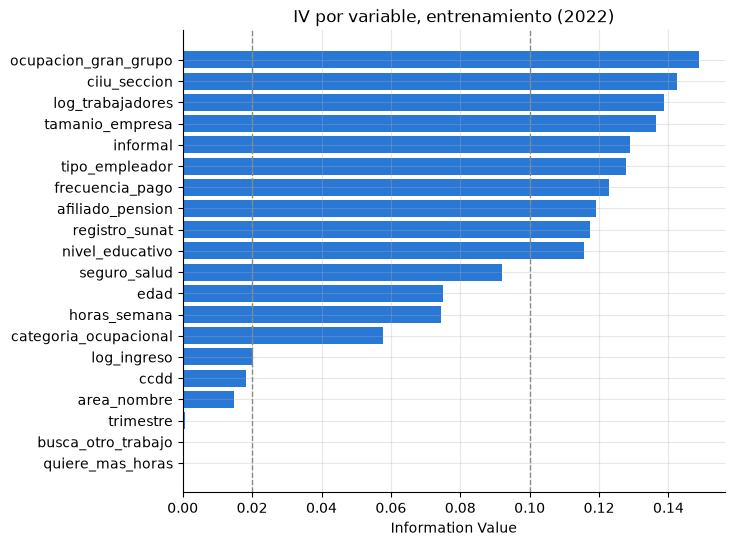

In [5]:
x_ent = preparar(particion.entrenamiento)
y_ent = particion.entrenamiento[OBJETIVO_PRINCIPAL].astype(int).to_numpy()
woe = {v: validacion.tabla_woe(x_ent[v], y_ent) for v in PREDICTORES}
iv = pd.Series({v: t["iv"].sum() for v, t in woe.items()}).sort_values()

fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(iv.index, iv, color=AZUL)
for corte in (0.02, 0.10):
    ax.axvline(corte, color=GRIS, linestyle="--", linewidth=1)
ax.set_xlabel("Information Value")
ax.set_title("IV por variable, entrenamiento (2022)")
plt.show()

In [6]:
def ver_woe(variable):
    t = woe[variable][["tramo", "n", "tasa_evento", "woe"]].copy()
    if variable in BOOLEANAS:
        t["tramo"] = t["tramo"].map({"0.0": "no", "1.0": "sí"})
    t["tasa_evento"] *= 100
    t.loc[t["n"] < 30, ["tasa_evento", "woe"]] = np.nan  # tramos chicos: sin tasa
    return (
        t.style.hide(axis="index")
        .format({"n": "{:,}", "tasa_evento": "{:.1f}", "woe": "{:.3f}"}, na_rep="")
        .set_caption(f"{variable} (IV = {woe[variable]['iv'].sum():.3f})")
    )


for variable in ["informal", "ocupacion_gran_grupo", "edad", "horas_semana"]:
    display(ver_woe(variable))

tramo,n,tasa_evento,woe
no,"16,774",26.0,0.547
sí,"34,419",43.6,-0.238


tramo,n,tasa_evento,woe
0,416,8.2,1.909
1,395,33.7,0.179
2,"5,308",20.7,0.843
3,"4,323",33.0,0.213
4,"3,276",28.8,0.407
5,"9,763",43.3,-0.229
6,"5,384",47.3,-0.388
7,"4,978",40.9,-0.129
8,"4,273",29.6,0.368
9,"13,077",43.2,-0.222


tramo,n,tasa_evento,woe
"(-inf, 23]","5,393",50.8,-0.528
"(23, 28]","5,167",35.5,0.099
"(28, 33]","5,734",35.6,0.094
"(33, 37]","4,812",33.6,0.182
"(37, 41]","4,856",34.1,0.163
"(41, 46]","5,776",32.8,0.218
"(46, 50]","4,300",33.6,0.186
"(50, 56]","5,684",34.9,0.127
"(56, 63]","4,920",37.1,0.032
"(63, inf]","4,551",51.1,-0.541


tramo,n,tasa_evento,woe
"(-inf, 15]","5,385",53.0,-0.616
"(15, 25]","5,083",44.4,-0.272
"(25, 35]","5,738",36.8,0.043
"(35, 40]","6,278",30.0,0.350
"(40, 45]","4,604",35.2,0.115
"(45, 48]","7,286",32.0,0.257
"(48, 50]","1,704",37.1,0.029
"(50, 57]","5,029",37.5,0.012
"(57, 68]","4,977",36.6,0.050
"(68, inf]","5,109",38.4,-0.025


Lo que más separa son las variables de formalidad: ocupación, sector, tamaño de la
empresa, informalidad, pensiones, registro en la Sunat. Tiene sentido: el empleo formal
y en empresas grandes pierde ingreso con menos frecuencia. La edad tiene forma de U, con
más riesgo en los más jóvenes y en los mayores, y las jornadas cortas son más riesgosas
que las completas.

El ingreso casi no separa por sí solo, aunque después es la variable que más usa el
modelo (sección 9): su relación con el evento no es lineal y depende de las demás. Querer
más horas y buscar otro trabajo no aportan nada solas. Ninguna variable pasa de 0,50.

## 5. Modelos

Comparo dos modelos para el evento principal:

- una regresión logística como baseline, con las categorías en variables binarias y las
  numéricas estandarizadas;
- un LightGBM con parada temprana sobre la cohorte 2023.

A los dos les aplico una regresión isotónica estimada con 2023 para pasar el puntaje a
probabilidad. También entreno un LightGBM para la pérdida de empleo, que uso como
contraste.

In [7]:
logistico = entrenar.entrenar_logistico(particion, OBJETIVO_PRINCIPAL)
boosting = entrenar.entrenar_boosting(particion, OBJETIVO_PRINCIPAL)
boosting_empleo = entrenar.entrenar_boosting(particion, OBJETIVO_CONTRASTE)

print("LightGBM:", entrenar.PARAMETROS_BOOSTING)
print(
    "árboles al parar:",
    boosting.estimador.best_iteration_,
    "(ingreso) y",
    boosting_empleo.estimador.best_iteration_,
    "(empleo)",
)

# el pipeline guardó estas métricas en el almacén; reentrenando tiene que dar lo mismo
publicadas = con.execute("SELECT * FROM marts.modelo_metricas").df()
for modelo, objetivo in (
    (logistico, OBJETIVO_PRINCIPAL),
    (boosting, OBJETIVO_PRINCIPAL),
    (boosting_empleo, OBJETIVO_CONTRASTE),
):
    nuevas = entrenar.evaluar(modelo, particion, objetivo)
    unidas = nuevas.merge(publicadas, on=["objetivo", "modelo", "parte"])
    for m in ("auc", "ks", "brier", "error_calibracion"):
        assert np.allclose(unidas[f"{m}_x"], unidas[f"{m}_y"], rtol=0, atol=1e-9)

LightGBM: {'objective': 'binary', 'learning_rate': 0.05, 'num_leaves': 31, 'min_child_samples': 100, 'subsample': 0.8, 'subsample_freq': 1, 'colsample_bytree': 0.8, 'reg_lambda': 1.0, 'n_estimators': 1000, 'random_state': 20261116, 'n_jobs': 1, 'deterministic': True, 'force_row_wise': True, 'verbose': -1}
árboles al parar: 214 (ingreso) y 109 (empleo)


## 6. Discriminación

De aquí en adelante todo es en la cohorte de prueba (2024), que el modelo no vio.

In [8]:
prueba = particion.prueba
y = prueba[OBJETIVO_PRINCIPAL].astype(int).to_numpy()
p_lgbm = boosting.probabilidad(prueba)
p_log = logistico.probabilidad(prueba)

comparacion = pd.DataFrame(
    {"logística": metricas.resumen(y, p_log), "LightGBM": metricas.resumen(y, p_lgbm)}
).T
comparacion["gini"] = 2 * comparacion["auc"] - 1
comparacion[["auc", "gini", "ks", "brier", "error_calibracion"]]

,auc,gini,ks,brier,error_calibracion
logística,0.654,0.309,0.221,0.216,0.024
LightGBM,0.699,0.398,0.282,0.206,0.025


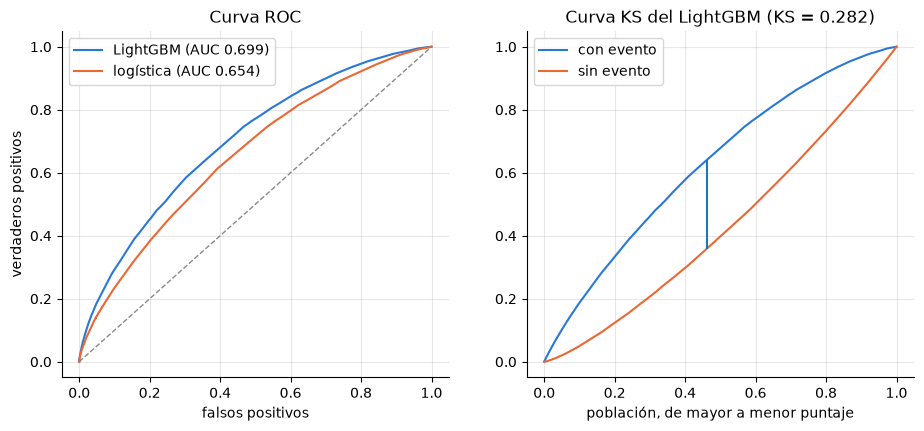

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
for nombre, p, color in (("LightGBM", p_lgbm, AZUL), ("logística", p_log, NARANJA)):
    fpr, tpr, _ = roc_curve(y, p)
    ax1.plot(fpr, tpr, color=color, label=f"{nombre} (AUC {metricas.auc(y, p):.3f})")
ax1.plot([0, 1], [0, 1], color=GRIS, linestyle="--", linewidth=1)
ax1.set_xlabel("falsos positivos")
ax1.set_ylabel("verdaderos positivos")
ax1.set_title("Curva ROC")
ax1.legend()

curva = validacion.curva_ks(y, p_lgbm)
punto = curva.loc[curva["distancia"].idxmax()]
ax2.plot(curva["poblacion"], curva["acumulado_eventos"], color=AZUL, label="con evento")
ax2.plot(curva["poblacion"], curva["acumulado_no_eventos"], color=NARANJA, label="sin evento")
ax2.vlines(punto["poblacion"], punto["acumulado_no_eventos"], punto["acumulado_eventos"])
ax2.set_title(f"Curva KS del LightGBM (KS = {punto['distancia']:.3f})")
ax2.set_xlabel("población, de mayor a menor puntaje")
ax2.legend()
plt.show()

In [10]:
deciles = validacion.tabla_deciles(y, p_lgbm)  # decil 1 = 10% con mayor probabilidad
deciles[["decil", "n", "prob_media", "tasa_observada", "captura_acumulada", "lift"]]

,decil,n,prob_media,tasa_observada,captura_acumulada,lift
0,1,4708,0.722,0.683,0.188,1.875
1,2,4707,0.583,0.531,0.333,1.458
2,3,4708,0.502,0.465,0.461,1.276
3,4,4707,0.452,0.427,0.578,1.171
4,5,4708,0.390,0.358,0.676,0.984
5,6,4707,0.364,0.348,0.772,0.954
6,7,4708,0.311,0.290,0.851,0.795
7,8,4707,0.260,0.238,0.917,0.654
8,9,4708,0.194,0.186,0.968,0.510
9,10,4708,0.116,0.118,1.000,0.323


El LightGBM ordena mejor que la logística (AUC, Gini y KS más altos, y menor Brier); en
error de calibración quedan prácticamente iguales. Su AUC no es alto, y es lo que se
puede esperar con este evento: una parte grande de la variación del ingreso
declarado de un año a otro es ruido que ninguna variable anticipa. Para el uso que tiene
el modelo, ordenar segmentos, lo importante se cumple: la tasa observada baja de decil
en decil.

## 7. Calibración

Comparo lo estimado con lo observado por decil, con el puntaje directo del LightGBM y
con la probabilidad después de la isotónica.

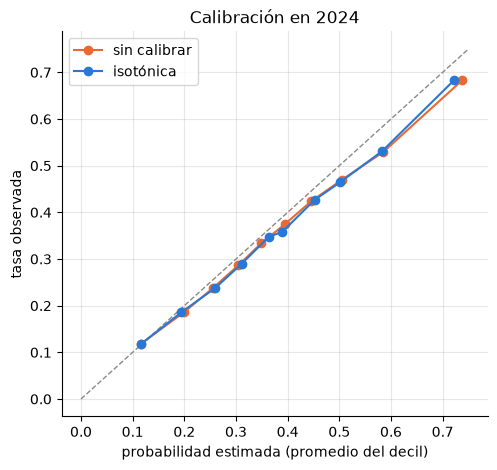

error de calibración: {'sin calibrar': 0.025, 'calibrado': 0.025}
estimado menos observado, en promedio: 2.5 puntos


In [11]:
puntaje = boosting.puntaje(prueba)
sin_calibrar = metricas.tabla_calibracion(y, puntaje)
calibrada = metricas.tabla_calibracion(y, p_lgbm)

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 0.75], [0, 0.75], color=GRIS, linestyle="--", linewidth=1)
ax.plot(
    sin_calibrar["estimado"], sin_calibrar["observado"], "o-", color=NARANJA, label="sin calibrar"
)
ax.plot(calibrada["estimado"], calibrada["observado"], "o-", color=AZUL, label="isotónica")
ax.set_xlabel("probabilidad estimada (promedio del decil)")
ax.set_ylabel("tasa observada")
ax.set_title("Calibración en 2024")
ax.legend()
plt.show()

errores = {
    "sin calibrar": metricas.error_de_calibracion(y, puntaje),
    "calibrado": metricas.error_de_calibracion(y, p_lgbm),
}
sesgo = 100 * (p_lgbm.mean() - y.mean())
print("error de calibración:", {k: round(v, 3) for k, v in errores.items()})
print(f"estimado menos observado, en promedio: {sesgo:.1f} puntos")

La isotónica casi no cambia el error, porque el LightGBM ya venía bien calibrado. La
dejo igual, porque protege contra un reentrenamiento que salga descalibrado.

Lo que sí queda es un sesgo de nivel: el modelo estima algo más de lo que pasó. La
calibración se hizo con 2023 y en 2024 el evento fue menos frecuente; eso no lo puede
anticipar ninguna calibración hecha con datos del pasado.

## 8. Estabilidad

PSI del puntaje entre la cohorte de entrenamiento y las otras dos, y CSI (la misma
fórmula) por variable. Uso los cortes habituales: menos de 0,10 es estable y de 0,10 a
0,25 hay que revisar.

In [12]:
estabilidad = entrenar.estabilidad(boosting, particion)
display(estabilidad)

x_cal = preparar(particion.validacion)
x_prueba = preparar(prueba)
csi = pd.DataFrame(
    {
        "2022 vs 2023": [validacion.csi(x_ent[v], x_cal[v]) for v in PREDICTORES],
        "2022 vs 2024": [validacion.csi(x_ent[v], x_prueba[v]) for v in PREDICTORES],
    },
    index=PREDICTORES,
)
display(csi.sort_values("2022 vs 2023", ascending=False).head(5))

# registro_sunat es la única que se mueve: ¿qué código cambia?
pd.DataFrame(
    {
        anio: x["registro_sunat"].value_counts()
        for anio, x in ((2022, x_ent), (2023, x_cal), (2024, x_prueba))
    }
).fillna(0).astype(int)

,modelo,comparacion,psi
0,boosting,entrenamiento contra validacion,0.002
1,boosting,entrenamiento contra prueba,0.005


,2022 vs 2023,2022 vs 2024
registro_sunat,0.192,0.001
trimestre,0.047,0.063
seguro_salud,0.008,0.011
ccdd,0.008,0.014
log_ingreso,0.007,0.013


,2022,2023,2024
registro_sunat,,,
(sin dato),8901,7698,7661
1,9122,8366,8510
2,7411,6455,6935
3,25759,22134,23970
4,0,882,0


El puntaje es estable. Entre las variables, la única que se mueve es `registro_sunat`
entre 2022 y 2023, y la última tabla muestra por qué: aparece un código 4 que solo está
en la base de 2023. Parece un cambio en cómo se codificó la pregunta y no en la
población (habría que confirmarlo con el diccionario del INEI); en 2024 vuelve a lo
normal.

Eso sí, en estos años no hubo una recesión, así que la estabilidad no dice cómo se
portaría el modelo en una crisis.

## 9. Qué variables pesan

Importancia con valores SHAP (`pred_contrib` de LightGBM): el promedio del valor
absoluto de la contribución de cada variable en la cohorte de prueba.

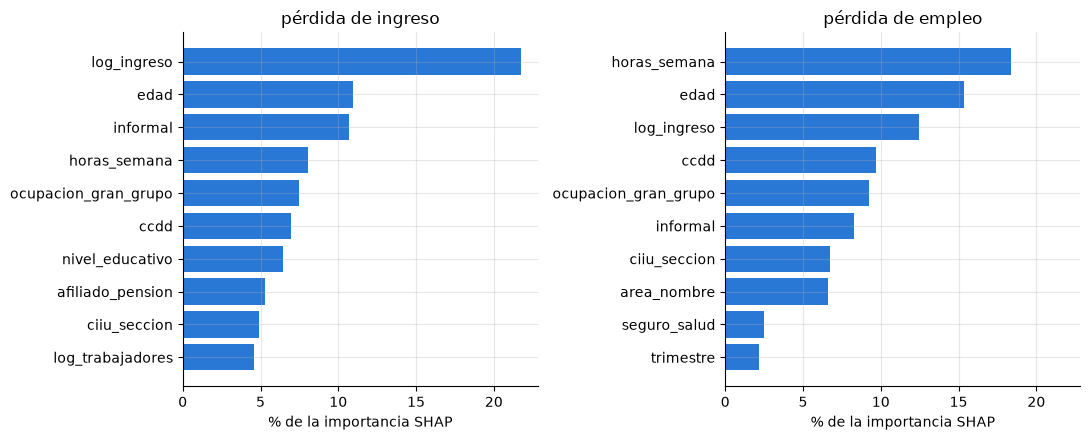

In [13]:
importancia = {
    "pérdida de ingreso": entrenar.importancia(boosting, prueba),
    "pérdida de empleo": entrenar.importancia(boosting_empleo, prueba),
}
fig, ejes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True)
for ax, (titulo, tabla) in zip(ejes, importancia.items(), strict=True):
    top = tabla.head(10).iloc[::-1]
    ax.barh(top["variable"], 100 * top["participacion"], color=AZUL)
    ax.set_title(titulo)
    ax.set_xlabel("% de la importancia SHAP")
plt.tight_layout()
plt.show()

En el modelo principal la variable que más pesa es el ingreso, y hay que leerlo con
cuidado. El evento se define con una caída del ingreso declarado, y quien declaró un
ingreso alto por azar en la primera entrevista tiende a declarar menos en la segunda
(regresión a la media). Parte de lo que aprende el modelo del ingreso es ese ruido.

Para eso sirve el modelo de empleo: ahí el ingreso pierde peso y suben las horas y la
edad. La informalidad, la ocupación y el departamento importan en los dos, y son las que
sostienen la lectura económica del puntaje.

## 10. Equidad

El modelo no usa sexo, lengua materna ni autoidentificación étnica. El sexo lo guardo
solo para revisar si el modelo trata distinto a hombres y mujeres.

In [14]:
auditoria = entrenar.auditar_por_grupo(boosting, prueba, OBJETIVO_PRINCIPAL, "sexo")
auditoria["estimado - observado (puntos)"] = 100 * (auditoria["estimado"] - auditoria["observado"])
auditoria

,variable,grupo,n,observado,estimado,auc,estimado - observado (puntos)
0,sexo,Hombre,24402,0.316,0.390,0.705,7.393
1,sexo,Mujer,22674,0.416,0.389,0.695,-2.741


Ordena casi igual de bien a hombres y mujeres (el AUC es parecido), pero falla en el
nivel: las mujeres pierden ingreso más seguido y el modelo, que no ve el sexo, les da
casi la misma probabilidad que a los hombres. Es el costo de no usar la variable. En la
práctica, un segmento con muchas mujeres recibe un puntaje algo optimista y conviene
leerlo junto con su composición por sexo.

## 11. Puntaje por segmento

Lo que se publica no es la probabilidad de cada persona, sino su promedio por segmento:
aplico el modelo a los ocupados de 2025 y promedio con el factor de expansión, con el
error estándar del diseño de la encuesta. El intervalo refleja el muestreo, no la
incertidumbre del modelo.

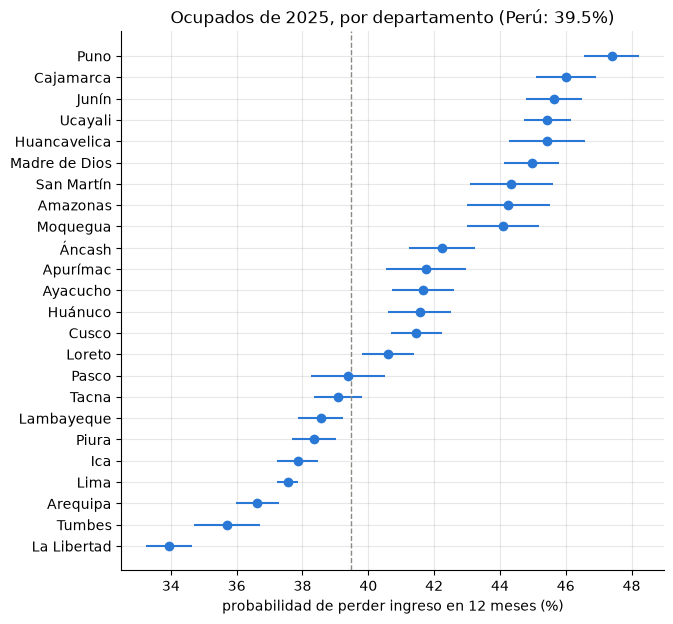

,rama_inei,score,bajo,alto,n
25,"Agricultura, pesca y minería",45.815,45.444,46.186,27801
27,Construcción,43.580,43.096,44.063,12594
26,Comercio,42.257,41.926,42.587,34970
28,Manufactura,38.918,38.426,39.410,13319
29,Servicios,34.905,34.663,35.146,87371


In [15]:
score = con.execute(
    """
    SELECT s.desagregacion, d.departamento, s.rama_inei, s.score, s.ee, s.n
    FROM marts.score_segmento AS s
    LEFT JOIN staging.dim_departamento AS d ON s.ccdd = d.ccdd
    WHERE s.objetivo = ? AND s.desagregacion IN ('nacional', 'departamento', 'rama')
    """,
    [OBJETIVO_PRINCIPAL],
).df()
nacional = score.loc[score["desagregacion"] == "nacional", "score"].iloc[0]

deptos = score[score["desagregacion"] == "departamento"].sort_values("score")
fig, ax = plt.subplots(figsize=(7, 7))
ax.errorbar(deptos["score"], deptos["departamento"], xerr=1.96 * deptos["ee"], fmt="o", color=AZUL)
ax.axvline(nacional, color=GRIS, linestyle="--", linewidth=1)
ax.set_xlabel("probabilidad de perder ingreso en 12 meses (%)")
ax.set_title(f"Ocupados de 2025, por departamento (Perú: {nacional:.1f}%)")
plt.show()

ramas = score[score["desagregacion"] == "rama"].sort_values("score", ascending=False)
ramas.assign(bajo=ramas["score"] - 1.96 * ramas["ee"], alto=ramas["score"] + 1.96 * ramas["ee"])[
    ["rama_inei", "score", "bajo", "alto", "n"]
]

Los extremos se separan bien, pero en el medio muchos intervalos se cruzan: el orden
fino entre esos departamentos no es firme. Entre sectores las diferencias son más
grandes que la incertidumbre.

## 12. Validación externa

Lo ideal sería comparar con la morosidad real por departamento, pero la SBS no la
publica. Armé una aproximación: la morosidad de cada banco, ponderada por lo que coloca
en cada departamento.

Spearman puntaje vs morosidad aproximada: 0.27
Spearman puntaje vs informalidad: 0.6
la morosidad aproximada va de 3.2% a 3.8% entre 24 departamentos


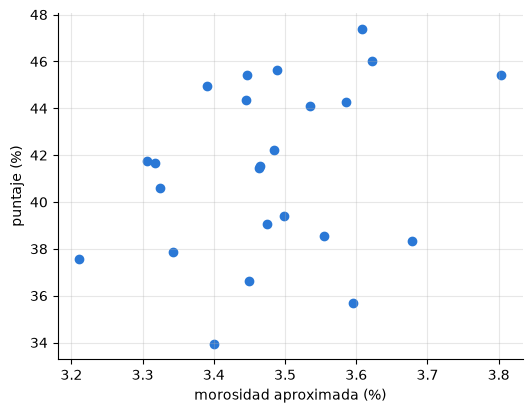

In [16]:
externa = con.execute("SELECT * FROM marts.modelo_validacion_externa").df()
print(
    "Spearman puntaje vs morosidad aproximada:",
    round(externa["score"].corr(externa["morosidad_proxy_pct"], method="spearman"), 2),
)
print(
    "Spearman puntaje vs informalidad:",
    round(externa["score"].corr(externa["tasa_informalidad"], method="spearman"), 2),
)
print(
    f"la morosidad aproximada va de {externa['morosidad_proxy_pct'].min():.1f}% "
    f"a {externa['morosidad_proxy_pct'].max():.1f}% entre {len(externa)} departamentos"
)

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(externa["morosidad_proxy_pct"], externa["score"], color=AZUL)
ax.set_xlabel("morosidad aproximada (%)")
ax.set_ylabel("puntaje (%)")
plt.show()

La relación es positiva pero débil, y no prueba nada en ningún sentido. La aproximación
casi no varía entre departamentos porque supone que cada banco tiene la misma morosidad
en todo el país, y además solo cubre bancos, no cajas ni financieras, que atienden a
buena parte de los informales. Para una validación externa de verdad hace falta un dato
de morosidad por departamento.

## 13. Limitaciones y monitoreo

- No es un modelo de crédito: mide pérdida de ingreso laboral, no impago.
- El ingreso es nominal; la caída de 30% no descuenta la inflación.
- Solo veo a quienes siguen en el panel. Si los que salen pierden ingreso con otra
  frecuencia, el evento está sesgado.
- Hay una sola cohorte de entrenamiento y ningún año de recesión.
- El puntaje de 2025 aplica a ocupados de 2025 un modelo entrenado con 2022.
- Queda el sesgo de nivel por sexo y falta una validación externa sólida.

Si el modelo se usara, propondría vigilar lo siguiente. Los cortes del PSI son los
habituales; los demás los ajustaría después del primer año.

| Indicador | Cada cuánto | Revisar desde | Actuar desde |
|---|---|---|---|
| PSI del puntaje | mensual | 0,10 | 0,25 |
| CSI por variable | mensual | 0,10 | 0,25 |
| tasa del evento frente a la de calibración | cada cohorte | 2 puntos | 5 puntos |
| error de calibración | cada cohorte | 0,03 | 0,05 |
| caída del AUC | cada cohorte | 0,03 | 0,05 |
| brecha estimado - observado por sexo | cada cohorte | 5 puntos | 8 puntos |

Si se pasa la calibración o la tasa del evento, recalibro la isotónica con la cohorte
más reciente; si es el PSI, el CSI o el AUC, reentreno. Abajo lo aplico a la cohorte de
prueba como si fuera el primer periodo.

In [17]:
p_cal = boosting.probabilidad(particion.validacion)
y_cal = particion.validacion[OBJETIVO_PRINCIPAL].astype(int)
psi_prueba = estabilidad["psi"].max()
tasa_cal = 100 * y_cal.mean()

# (valor, revisar desde, actuar desde)
chequeo = pd.DataFrame(
    {
        "PSI del puntaje": (psi_prueba, 0.10, 0.25),
        f"CSI máximo ({csi.max(axis=1).idxmax()})": (csi.max().max(), 0.10, 0.25),
        "tasa del evento vs calibración (puntos)": (abs(100 * y.mean() - tasa_cal), 2, 5),
        "error de calibración": (errores["calibrado"], 0.03, 0.05),
        "caída del AUC": (metricas.auc(y_cal, p_cal) - metricas.auc(y, p_lgbm), 0.03, 0.05),
        "brecha por sexo (puntos)": (auditoria["estimado - observado (puntos)"].abs().max(), 5, 8),
    },
    index=["valor", "revisar", "actuar"],
).T
chequeo["estado"] = np.select(
    [chequeo["valor"] < chequeo["revisar"], chequeo["valor"] <= chequeo["actuar"]],
    ["verde", "ámbar"],
    "rojo",
)
chequeo

,valor,revisar,actuar,estado
PSI del puntaje,0.005,0.100,0.250,verde
CSI máximo (registro_sunat),0.192,0.100,0.250,ámbar
tasa del evento vs calibración (puntos),1.898,2.000,5.000,verde
error de calibración,0.025,0.030,0.050,verde
caída del AUC,0.011,0.030,0.050,verde
brecha por sexo (puntos),7.393,5.000,8.000,ámbar


## Resumen

- El LightGBM ordena mejor que la logística, con una discriminación moderada. Sirve
  para comparar segmentos, no para decidir sobre una persona.
- Es estable entre cohortes. En 2024 mantiene el orden pero estima un nivel algo más
  alto que el observado, porque ese año el evento fue menos frecuente.
- El ingreso es lo que más pesa, en parte por regresión a la media; las variables de
  formalidad, la ocupación y el departamento sostienen el resultado en los dos modelos.
- Lo que queda fuera del verde en el monitoreo es lo que ya había aparecido: el código
  nuevo de `registro_sunat` y la brecha por sexo.

In [18]:
con.close()